Import Neo4j dan password

driver.execute_query("MATCH (n) DETACH DELETE n", database_="neo4j")

Tahap 0: Persiapan (soal 1.1 dan 1.2)

In [ ]:
import getpass
URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", getpass.getpass("Password Neo4j: "))

Terhubung!


1. Tugas Pendahuluan
1.2 Tutorial driver Neo4j

Sel 1: fungsi tutorial dan eksekusi

In [ ]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_="neo4j",
    )

def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_="neo4j", routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

In [ ]:
with GraphDatabase.driver(URI, auth=AUTH) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


Sel 2: reset database

In [ ]:
driver = GraphDatabase.driver(URI, auth=AUTH)
driver.execute_query("MATCH (n) DETACH DELETE n", database_="neo4j")
print("Database kosong lagi.")

Database kosong lagi.


In [ ]:
records, _, _ = driver.execute_query("MATCH (n) RETURN count(n) AS jumlah", database_="neo4j")
print(records[0]["jumlah"])   # harus 0

0


2.1 Wrangling dan EDA (45 poin)
Soal 1: Tentukan 2 periode

Sel 3: cek rentang data

In [ ]:
import pandas as pd

df = pd.read_csv("data/events.csv")
df["tanggal"] = pd.to_datetime(df["timestamp"], unit="ms")
print(df.shape)
print(df["tanggal"].min(), df["tanggal"].max())
print(df["event"].value_counts())

(2756101, 6)
2015-05-03 03:00:04.384000 2015-09-18 02:59:47.788000
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64


Soal 2: Filter dan simpan CSV
(P1: 2015-05-15 sampai 2015-05-30, P2: 2015-09-01 sampai 2015-09-16)

In [ ]:
import pandas as pd
import os

df = pd.read_csv("data/events.csv")
df["tanggal"] = pd.to_datetime(df["timestamp"], unit="ms")

# batas akhir dibuat eksklusif (hari berikutnya) supaya tanggal 30 Mei dan 16 Sep ikut penuh
p1 = df[(df["tanggal"] >= "2015-05-15") & (df["tanggal"] < "2015-05-31")].drop(columns="tanggal")
p2 = df[(df["tanggal"] >= "2015-09-01") & (df["tanggal"] < "2015-09-17")].drop(columns="tanggal")

os.makedirs("data", exist_ok=True)
p1.to_csv("data/events_p1.csv", index=False)
p2.to_csv("data/events_p2.csv", index=False)

print("P1:", p1.shape, "| visitor:", p1.visitorid.nunique(), "| item:", p1.itemid.nunique())
print("P2:", p2.shape, "| visitor:", p2.visitorid.nunique(), "| item:", p2.itemid.nunique())
print(p1["event"].value_counts())
print(p2["event"].value_counts())

P1: (340322, 5) | visitor: 182268 | item: 85839
P2: (292054, 5) | visitor: 167349 | item: 80419
event
view           329719
addtocart        8011
transaction      2592
Name: count, dtype: int64
event
view           282351
addtocart        7394
transaction      2309
Name: count, dtype: int64


Sel 5: cek overlap

In [ ]:
v_both = set(p1.visitorid) & set(p2.visitorid)
i_both = set(p1.itemid) & set(p2.itemid)
print("Visitor di P1 dan P2:", len(v_both))
print("Item di P1 dan P2:", len(i_both))

Visitor di P1 dan P2: 2160
Item di P1 dan P2: 39124


Impor P1 ke Neo4j (soal 1.3 no. 4 dan 5)
Sel 6: constraint dan fungsi impor

In [ ]:
import pandas as pd
from tqdm import tqdm

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()

def create_constraints(session):
    session.run("CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)

        UNION ALL

        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

Sel 7: jalankan impor

In [ ]:
csv_file_path = "data/events_p1.csv"
batch_size = 10000
total_rows = len(pd.read_csv(csv_file_path, usecols=["timestamp"]))
total_chunks = (total_rows // batch_size) + 1

with driver.session(database="neo4j") as session:
    create_constraints(session)
    chunks = pd.read_csv(csv_file_path, chunksize=batch_size)

    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
        # transactionid bertipe float (ada NaN), jadi diubah manual agar tidak menjadi "123.0"
        chunk["transactionid"] = chunk["transactionid"].apply(
            lambda x: "" if pd.isna(x) else str(int(x))
        )
        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

print("Proses impor selesai.")

Mengimpor Batch Data: 100%|██████████| 35/35 [00:53<00:00,  1.53s/it]

Proses impor selesai.


Soal 3: Komposisi subgraph

In [ ]:
q_node = "MATCH (n) RETURN labels(n)[0] AS jenis, count(*) AS jumlah"
q_rel = "MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah"

for q in (q_node, q_rel):
    records, _, _ = driver.execute_query(q, database_="neo4j")
    for r in records:
        print(dict(r))

{'jenis': 'Visitor', 'jumlah': 182268}
{'jenis': 'Item', 'jumlah': 85839}
{'relasi': 'VIEWED', 'jumlah': 329719}
{'relasi': 'ADDED_TO_CART', 'jumlah': 8011}
{'relasi': 'BOUGHT', 'jumlah': 2592}


In [ ]:
import logging
logging.getLogger("neo4j.notifications").setLevel(logging.ERROR)

Soal 3: komposisi subgraph. Jalankan query berikut dari Python dan jelaskan cara kerjanya:

MATCH (n) RETURN labels(n)[0] AS jenis, count(*): MATCH (n) mengambil semua node, labels(n)[0] mengambil label pertama tiap node (Visitor atau Item), lalu count(*) menghitung jumlah per label (pengelompokan terjadi otomatis karena jenis ada di RETURN).
MATCH ()-[r]->() RETURN type(r), count(*): sama, tapi untuk relasi. type(r) memberi nama tipenya.
Strukturnya graf bipartit berarah: Visitor → Item, dengan 3 tipe relasi (multigraf, karena satu visitor bisa melakukan banyak event ke item yang sama).

Soal 4 dan 5: VSM
Sel 9: tarik data dari Neo4j

In [ ]:
q = """
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN v.visitorId AS visitor, i.itemId AS item, type(r) AS event
"""
records, _, _ = driver.execute_query(q, database_="neo4j")
edges = pd.DataFrame([dict(r) for r in records])
print(edges.shape)
edges.head()

(340322, 3)


,visitor,item,event
0,310356,454137,VIEWED
1,310356,454137,VIEWED
2,310356,454137,VIEWED
3,310356,454137,VIEWED
4,310356,454137,VIEWED


Sel 10: matriks sparse

In [ ]:
import numpy as np
from scipy.sparse import csr_matrix

bobot = {"VIEWED": 1, "ADDED_TO_CART": 3, "BOUGHT": 5}
edges["w"] = edges["event"].map(bobot)

# satu pasangan (visitor, item) dapat banyak event, ambil bobot tertinggi
pair = edges.groupby(["visitor", "item"], as_index=False)["w"].max()

u_idx, u_labels = pd.factorize(pair["visitor"])
i_idx, i_labels = pd.factorize(pair["item"])

# VSM User: baris = user, kolom = item
M_user = csr_matrix((pair["w"], (u_idx, i_idx)), shape=(len(u_labels), len(i_labels)))
# VSM Item: baris = item, kolom = user (transpose)
M_item = M_user.T.tocsr()

def info(M, nama):
    total = M.shape[0] * M.shape[1]
    print(f"{nama}: shape={M.shape}, non-zero={M.nnz}, "
          f"sparsity={100*(1-M.nnz/total):.4f}%, dtype={M.dtype}")

info(M_user, "VSM User")
info(M_item, "VSM Item")

VSM User: shape=(182268, 85839), non-zero=267079, sparsity=99.9983%, dtype=int64
VSM Item: shape=(85839, 182268), non-zero=267079, sparsity=99.9983%, dtype=int64


Sel 11: karakteristik vektor

In [ ]:
deg_user = np.diff(M_user.indptr)        # jumlah item unik per user
deg_item = np.diff(M_item.indptr)        # jumlah user unik per item

print("User : rata-rata item/user =", deg_user.mean().round(2),
      "| median =", np.median(deg_user), "| max =", deg_user.max())
print("Item : rata-rata user/item =", deg_item.mean().round(2),
      "| median =", np.median(deg_item), "| max =", deg_item.max())
print("User dengan hanya 1 interaksi:", (deg_user == 1).sum(),
      f"({100*(deg_user==1).mean():.1f}%)")

User : rata-rata item/user = 1.47 | median = 1.0 | max = 819
Item : rata-rata user/item = 3.11 | median = 1.0 | max = 360
User dengan hanya 1 interaksi: 148002 (81.2%)


Sel 12: plot networkx untuk User

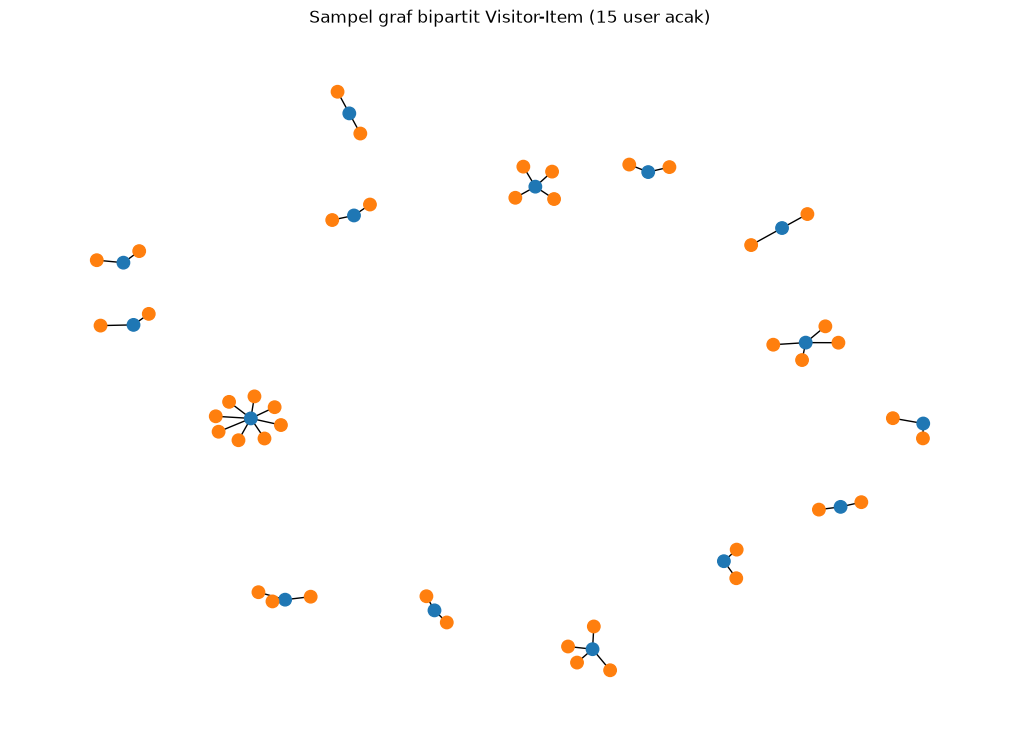

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

rng = np.random.default_rng(42)
kandidat = np.where(deg_user >= 2)[0]
sampel_u = rng.choice(kandidat, size=15, replace=False)

sub = pair[pair["visitor"].isin(u_labels[sampel_u])]

G = nx.Graph()

for _, r in sub.iterrows():
    visitor = int(r["visitor"])
    item = int(r["item"])

    G.add_node(f"U{visitor}", tipe="user")
    G.add_node(f"I{item}", tipe="item")
    G.add_edge(f"U{visitor}", f"I{item}", weight=r["w"])

warna = [
    "tab:blue" if G.nodes[n]["tipe"] == "user" else "tab:orange"
    for n in G
]

plt.figure(figsize=(10, 7))

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos=pos,
    node_color=warna,
    node_size=80,
    with_labels=False
)

plt.title("Sampel graf bipartit Visitor-Item (15 user acak)")
plt.show()

Soal 6: Proyeksi mana yang lebih baik
Sel 14: estimasi ukuran proyeksi

In [ ]:
# jumlah pasangan yang berpotensi terhubung di tiap proyeksi
pasangan_user = int((deg_item * (deg_item - 1) // 2).sum())  # user-user: dua user berbagi item
pasangan_item = int((deg_user * (deg_user - 1) // 2).sum())  # item-item: dua item dibuka user yang sama

print("Potensi edge proyeksi user-user:", f"{pasangan_user:,}")
print("Potensi edge proyeksi item-item:", f"{pasangan_item:,}")

Potensi edge proyeksi user-user: 1,994,329
Potensi edge proyeksi item-item: 1,662,840


Sel 13: plot networkx untuk Item

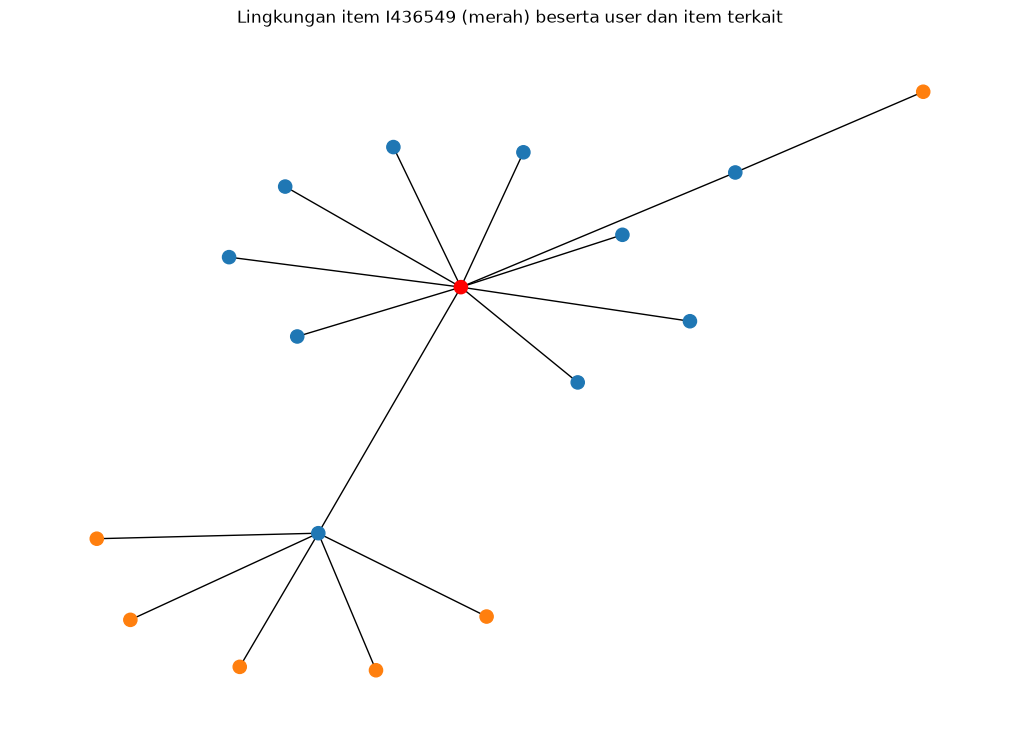

In [ ]:
rng = np.random.default_rng(42)

cand = np.where((deg_item >= 5) & (deg_item <= 15))[0]
i0 = rng.choice(cand)

users = M_item[i0].indices
users = users[deg_user[users] <= 10]

sub = pair[pair["visitor"].isin(u_labels[users])]

G = nx.Graph()

for _, r in sub.iterrows():
    visitor = int(r["visitor"])
    item = int(r["item"])

    G.add_node(f"U{visitor}", tipe="user")
    G.add_node(f"I{item}", tipe="item")
    G.add_edge(f"U{visitor}", f"I{item}")

fokus = f"I{int(i_labels[i0])}"

warna = [
    "red" if n == fokus
    else ("tab:blue" if G.nodes[n]["tipe"] == "user" else "tab:orange")
    for n in G
]

plt.figure(figsize=(10, 7))

pos = nx.spring_layout(G, seed=42)
nx.draw(
    G,
    pos=pos,
    node_color=warna,
    node_size=90,
    with_labels=False
)

plt.title(f"Lingkungan item {fokus} (merah) beserta user dan item terkait")
plt.show()

Sel 15: proyeksi sebenarnya

In [ ]:
from scipy.sparse.csgraph import connected_components
import time

def proyeksi(M, nama):
    t = time.time()
    B = (M > 0).astype(np.int32)        # biner: berbagi tetangga atau tidak
    P = (B @ B.T).tocsr()               # nilai = jumlah tetangga bersama
    P.setdiag(0)
    P.eliminate_zeros()
    n = P.shape[0]
    deg = np.diff(P.indptr)
    n_comp, _ = connected_components(P, directed=False)
    print(f"{nama}: node={n:,} | edge={P.nnz//2:,} | density={100*P.nnz/(n*(n-1)):.5f}% | "
          f"node terisolasi={(deg==0).sum():,} | komponen={n_comp:,} | waktu={time.time()-t:.1f}s")
    return P

P_user = proyeksi(M_user, "User-user")
P_item = proyeksi(M_item, "Item-item")

User-user: node=182,268 | edge=1,931,222 | density=0.01163% | node terisolasi=31,474 | komponen=44,571 | waktu=0.6s
Item-item: node=85,839 | edge=1,591,054 | density=0.04319% | node terisolasi=40,955 | komponen=44,571 | waktu=0.3s


Soal 7: hitung similarity

In [ ]:
import numpy as np

# Pilih dua item yang ingin dibandingkan
a = 0
b = 1

# User yang berinteraksi dengan masing-masing item
users_a = set(M_item[a].indices)
users_b = set(M_item[b].indices)

# Hitung jumlah user bersama
user_bersama = len(users_a & users_b)

# Derajat masing-masing item
deg_a = len(users_a)
deg_b = len(users_b)

# Cosine similarity
cosine = user_bersama / np.sqrt(deg_a * deg_b) if deg_a * deg_b > 0 else 0

print("User bersama:", user_bersama)
print("Derajat item A:", deg_a)
print("Derajat item B:", deg_b)
print("Cosine similarity:", cosine)

User bersama: 0
Derajat item A: 2
Derajat item B: 5
Cosine similarity: 0.0


Soal 7: Similarity
Sel 16: item acuan, top-5 versi Python (7a)

In [ ]:
rng = np.random.default_rng(42)
cand = np.where((deg_item >= 20) & (deg_item <= 100))[0]
ref = rng.choice(cand)
ref_id = int(i_labels[ref])

row = P_item[ref].tocoo()
cols, inter = row.col, row.data
cos = inter / np.sqrt(deg_item[ref] * deg_item[cols])
order = np.lexsort((-inter, -cos))[:5]      # urut cosine, seri diputus oleh user_bersama

hasil_py = pd.DataFrame({
    "item": [int(i_labels[c]) for c in cols[order]],
    "user_bersama": inter[order],
    "cosine": cos[order].round(4),
})
print("Item acuan:", ref_id, "| jumlah user:", deg_item[ref])
hasil_py

Item acuan: 158666 | jumlah user: 93


,item,user_bersama,cosine
0,60681,2,0.1197
1,278812,1,0.1037
2,9486,1,0.1037
3,350635,1,0.1037
4,443867,1,0.1037


Sel 17: top-5 versi Cypher (7a)

In [ ]:
q_top5 = """
MATCH (a:Item {itemId: $ref})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)
WITH a, collect(DISTINCT v) AS va
UNWIND va AS v
MATCH (v)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(b:Item)
WHERE b <> a
WITH a, size(va) AS da, b, count(DISTINCT v) AS inter
MATCH (b)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(vb:Visitor)
WITH a, da, b, inter, count(DISTINCT vb) AS db
RETURN b.itemId AS item, inter AS user_bersama, da, db,
       toFloat(inter) / sqrt(toFloat(da) * db) AS cosine
ORDER BY cosine DESC, user_bersama DESC
LIMIT 5
"""
records, _, _ = driver.execute_query(q_top5, ref=ref_id, database_="neo4j")
hasil_cy = pd.DataFrame([dict(r) for r in records])
hasil_cy

,item,user_bersama,da,db,cosine
0,60681,2,93,3,0.119737
1,270304,1,93,1,0.103695
2,350635,1,93,1,0.103695
3,278812,1,93,1,0.103695
4,410156,1,93,1,0.103695


Sel 18: hapus SIMILAR_TO supaya kondisi “sebelum” valid

In [89]:
driver.execute_query("MATCH ()-[s:SIMILAR_TO]->() DELETE s", database_="neo4j")

q_count = "MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah ORDER BY relasi"
records, _, _ = driver.execute_query(q_count, database_="neo4j")
print("SEBELUM:", [dict(r) for r in records])

SEBELUM: [{'relasi': 'ADDED_TO_CART', 'jumlah': 8011}, {'relasi': 'BOUGHT', 'jumlah': 2592}, {'relasi': 'VIEWED', 'jumlah': 329719}]


In [105]:
# Tampilkan hubungan asli Visitor dan Item sebelum similarity
q_before = f"""
MATCH (a:Item {{itemId: {ref_id}}})
OPTIONAL MATCH p = (a)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)
RETURN a, p
"""

print(q_before)


MATCH (a:Item {itemId: 158666})
OPTIONAL MATCH p = (a)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(v:Visitor)
RETURN a, p



Sel 19: cetak query visualisasi after

In [99]:
ids = [int(x) for x in hasil_cy["item"]]
q_vis = f"""MATCH (a:Item {{itemId: {ref_id}}})
MATCH (b:Item) WHERE b.itemId IN {ids}
OPTIONAL MATCH p1=(a)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(b)
OPTIONAL MATCH p2=(a)-[:SIMILAR_TO]->(b)
RETURN a, b, p1, p2"""
print(q_vis)

MATCH (a:Item {itemId: 158666})
MATCH (b:Item) WHERE b.itemId IN [60681, 270304, 350635, 278812, 410156]
OPTIONAL MATCH p1=(a)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(b)
OPTIONAL MATCH p2=(a)-[:SIMILAR_TO]->(b)
RETURN a, b, p1, p2


Soal 7(b): Tulis balik similarity ke graf

In [107]:
q_write = """
UNWIND $rows AS row
MATCH (a:Item {itemId: $ref}), (b:Item {itemId: row.item})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.cosine, s.metode = 'cosine_biner'
"""
rows = [{"item": int(r.item), "cosine": float(r.cosine)} for r in hasil_cy.itertuples()]
driver.execute_query(q_write, ref=ref_id, rows=rows, database_="neo4j")

cek, _, _ = driver.execute_query("""
MATCH (a:Item {itemId: $ref})-[s:SIMILAR_TO]->(b:Item)
RETURN a.itemId AS acuan, b.itemId AS mirip, s.score AS score
ORDER BY score DESC
""", ref=ref_id, database_="neo4j")
display(pd.DataFrame([dict(r) for r in cek]))

records, _, _ = driver.execute_query(q_count, database_="neo4j")
print("SESUDAH:", [dict(r) for r in records])

,acuan,mirip,score
0,158666,60681,0.119737
1,158666,270304,0.103695
2,158666,410156,0.103695
3,158666,278812,0.103695
4,158666,350635,0.103695


SESUDAH: [{'relasi': 'ADDED_TO_CART', 'jumlah': 8011}, {'relasi': 'BOUGHT', 'jumlah': 2592}, {'relasi': 'SIMILAR_TO', 'jumlah': 5}, {'relasi': 'VIEWED', 'jumlah': 329719}]


In [94]:
print(f"""MATCH p=(a:Item {{itemId: {ref_id}}})-[:SIMILAR_TO]->(b:Item)
OPTIONAL MATCH q=(a)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(b)
RETURN p, q""")

MATCH p=(a:Item {itemId: 158666})-[:SIMILAR_TO]->(b:Item)
OPTIONAL MATCH q=(a)<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(b)
RETURN p, q


In [95]:
print(ref_id)

158666


2.2 Analytics (55 poin)
Sel 21: siapkan data

In [108]:
p2 = pd.read_csv("data/events_p2.csv")

i_arr = np.asarray(i_labels)
u_arr = np.asarray(u_labels)
i_pos = pd.Series(np.arange(len(i_arr)), index=i_arr)
u_pos = pd.Series(np.arange(len(u_arr)), index=u_arr)
pdeg = np.diff(P_item.indptr)                    # jumlah tetangga tiap item di proyeksi

overlap = np.intersect1d(u_arr, p2["visitorid"].unique())
katalog = set(i_arr.tolist())

p1_hist = pair[pair["visitor"].isin(overlap)].groupby("visitor")["item"].apply(set)
p2_items = p2[p2["visitorid"].isin(overlap)].groupby("visitorid")["itemid"].apply(set)

def ground_truth(v):
    return (p2_items[v] & katalog) - p1_hist[v]

eligible = [int(v) for v in sorted(overlap)
            if ground_truth(v) and any(pdeg[i_pos[i]] > 0 for i in p1_hist[v])]
print("Visitor overlap P1&P2:", len(overlap), "| layak dievaluasi:", len(eligible))

Visitor overlap P1&P2: 2160 | layak dievaluasi: 1097


Soal 1a dan 1b: User acak dan KNN
Sel 22: pilih user acak

In [109]:
SEED = 73          # boleh diganti NIM-mu; yang penting dicatat dan tidak diubah lagi
rng = np.random.default_rng(SEED)
user_id = int(rng.choice(eligible))

print("User terpilih:", user_id)
print("Item di P1  :", sorted(p1_hist[user_id]))
print("Ground truth P2:", sorted(ground_truth(user_id)))

User terpilih: 1171914
Item di P1  : [100735, 389860]
Ground truth P2: [165664]


Sel 23: KNN item-based

In [84]:
def knn_item(s, k, exclude):
    """k tetangga terdekat (cosine) dari item indeks s, tanpa item yang sudah dilihat user."""
    row = P_item[s].tocoo()
    cols, inter = row.col, row.data
    cos = inter / np.sqrt(deg_item[s] * deg_item[cols])
    keep = ~np.isin(cols, list(exclude))
    cols, cos = cols[keep], cos[keep]
    order = np.lexsort((i_arr[cols], -cos))[:k]      # seri diputus oleh itemId terkecil
    return cols[order], cos[order]

def recommend_item_knn(user_id, k=5, topn=5):
    row = M_user[u_pos[user_id]]                     # vektor user: indices = item, data = bobot
    seen = set(row.indices)
    skor = {}
    for s, w in zip(row.indices, row.data):
        nb, cs = knn_item(s, k, seen)
        for c, cv in zip(nb, cs):
            skor[c] = skor.get(c, 0.0) + w * cv      # bobot seed x cosine
    ranked = sorted(skor.items(), key=lambda x: (-x[1], i_arr[x[0]]))[:topn]
    return [(int(i_arr[c]), round(float(sc), 4)) for c, sc in ranked]

rekom = recommend_item_knn(user_id, k=5, topn=5)
rank_ids = [i for i, _ in rekom]
iklan = rank_ids[:3]

print("Peringkat rekomendasi (top-5):", rekom)
print("3 item yang diiklankan (k=5):", iklan)

Peringkat rekomendasi (top-5): [(37349, 0.3015), (58455, 0.291), (111140, 0.2722), (287038, 0.2722), (388073, 0.2722)]
3 item yang diiklankan (k=5): [37349, 58455, 111140]


Sel 24 (opsional): versi user-based

In [85]:
B_user = (M_user > 0).astype(np.float32).tocsr()

def recommend_user_knn(user_id, k=5, topn=5):
    ui = u_pos[user_id]
    inter = (B_user @ B_user[ui].T).toarray().ravel()
    cos = inter / (np.sqrt(deg_user) * np.sqrt(deg_user[ui]))
    cos[ui] = 0
    nb = np.lexsort((u_arr, -cos))[:k]
    nb = nb[cos[nb] > 0]                             # hanya tetangga yang benar-benar berbagi item
    skor = M_user[nb].T.dot(cos[nb])                 # jumlah (cosine x bobot) per item
    skor[M_user[ui].indices] = 0                     # buang item yang sudah dilihat
    top = np.lexsort((i_arr, -skor))[:topn]
    return [(int(i_arr[c]), round(float(skor[c]), 4)) for c in top if skor[c] > 0]

print(recommend_user_knn(user_id))

[(314553, 0.8165)]


Soal 2a dan 2b: Hit@5 dan NDCG@5
Sel 25

In [86]:
def hit_at_k(rec, gt, k=5):
    return int(any(i in gt for i in rec[:k]))

def ndcg_at_k(rec, gt, k=5):
    dcg = sum(1 / np.log2(r + 2) for r, i in enumerate(rec[:k]) if i in gt)
    idcg = sum(1 / np.log2(r + 2) for r in range(min(len(gt), k)))
    return dcg / idcg

gt = ground_truth(user_id)
print("Ground truth:", len(gt), "item")
print("Daftar iklan (3) -> Hit@5:", hit_at_k(iklan, gt), "| NDCG@5:", round(ndcg_at_k(iklan, gt), 4))
print("Top-5 penuh      -> Hit@5:", hit_at_k(rank_ids, gt), "| NDCG@5:", round(ndcg_at_k(rank_ids, gt), 4))

Ground truth: 1 item
Daftar iklan (3) -> Hit@5: 0 | NDCG@5: 0.0
Top-5 penuh      -> Hit@5: 0 | NDCG@5: 0.0


Hit@5: bernilai 1 kalau minimal satu item rekomendasi muncul di ground truth, selain itu 0.
NDCG@5: nilai DCG dari posisi item yang benar (rel / log2(posisi+1)), dibagi DCG ideal.

Sel 26: evaluasi 200 user

In [87]:
rng2 = np.random.default_rng(SEED)
sampel = rng2.choice(eligible, size=min(200, len(eligible)), replace=False)

hits, ndcgs = [], []
for v in sampel:
    r = [i for i, _ in recommend_item_knn(int(v), k=5, topn=5)]
    g = ground_truth(int(v))
    hits.append(hit_at_k(r, g)); ndcgs.append(ndcg_at_k(r, g))

print(f"{len(sampel)} user -> Hit@5 rata-rata: {np.mean(hits):.3f} | NDCG@5 rata-rata: {np.mean(ndcgs):.3f}")

200 user -> Hit@5 rata-rata: 0.010 | NDCG@5 rata-rata: 0.007


Sel 27 (opsional): baseline popularitas

In [88]:
pop_order = np.argsort(-deg_item, kind="stable")      # item paling banyak disentuh user di P1

def recommend_popular(user_id, topn=5):
    seen = set(M_user[u_pos[user_id]].indices)
    out = []
    for c in pop_order:
        if c not in seen:
            out.append(int(i_arr[c]))
            if len(out) == topn:
                break
    return out

hits_p, ndcgs_p = [], []
for v in sampel:
    r = recommend_popular(int(v))
    g = ground_truth(int(v))
    hits_p.append(hit_at_k(r, g)); ndcgs_p.append(ndcg_at_k(r, g))

print(f"Popularitas -> Hit@5: {np.mean(hits_p):.3f} | NDCG@5: {np.mean(ndcgs_p):.3f}")
print(f"KNN item    -> Hit@5: {np.mean(hits):.3f} | NDCG@5: {np.mean(ndcgs):.3f}")

Popularitas -> Hit@5: 0.000 | NDCG@5: 0.000
KNN item    -> Hit@5: 0.010 | NDCG@5: 0.007
